# INR reconstruction of a real even/odd tilt-series

The method of `INR_even_odd.ipynb`, applied to the real tilt-series `tomo200528_110` (Warp, 200 kV, 35 tilts from
+57° to −45° in 3° steps, frame-split even/odd halves, aligned, tilt axis along y, **not** CTF corrected). This notebook
holds the best approach so far, on the 10 Å central crop (320 × 320 px). The scripts in `inr_real/` contain the same
code plus the options that were tested and dropped (see the notes at the end).

* **Forward model**: line integral along parallel rays → −CTF (raw, teamtomo sign; per-tilt defocus and astigmatism
  from the Warp XML) × dose attenuation × cos(tilt) × learned gain + learned offset per tilt.
* **Model**: dense multi-resolution feature grids (cells 12 … 1 model voxels of 20 Å) + small MLP, softplus output
  (positivity).
* **Prior**: second-order TV (L1 norm of the finite-difference Hessian), weight 3.
* **Sampler**: each optimiser step accumulates gradients over the *whole images* of 10 randomly chosen tilts, so every
  step sees the whole volume from many directions. This replaced 2 random patches per step: the same validation loss
  in ~190 instead of 1500 steps, and no horizontal-line / patchy-blur artefacts in the predicted projections.
* **Gold standard**: one INR per half; the loss on the other half picks the checkpoint
  ($\mathbb{E}\|Pf - y_{odd}\|^2 = \|Pf - y_{clean}\|^2 + \sigma^2$ as long as $f$ never saw the odd noise).
* **Post-processing**: average, half-map FSC and FSC weighting, and optionally a Noise2Noise denoiser trained between
  the two INR volumes.

Training takes about 45 min per half on the M-series GPU (MPS). With `TRAIN = False` the notebook loads the checkpoints
in `runs/` when they exist and only trains what is missing.

In [1]:
from pathlib import Path
import copy
import math
import time
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import mrcfile
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import binary_dilation, uniform_filter
from torch_ctf import calculate_ctf_2d
from torch_fourier_filter.dose_weight import _apply_voltage_correction, _critical_exposure_grid
from torch_grid_utils import fftfreq_grid
from torch_affine_utils.transforms_3d import Ry

DATA = Path("data/real")
RUNS = Path("runs")
NAME = "tomo200528_110_crop"  # 10 A central crop of tomo200528_110
PIXEL_SPACING = 10.0  # A per detector pixel
MODEL_VOXEL = 20.0  # model coordinates are in units of 20 A at any pixel size
DETECTOR_SCALE = PIXEL_SPACING / MODEL_VOXEL  # detector pixel -> model units
REF_NY, REF_NX = 160, 160  # field of view in model voxels (the crop at 20 A), defines the box
THICKNESS = 300 * 10 / MODEL_VOXEL  # 300 nm, in model voxels
CELLS = (12, 8, 6, 4, 3, 2, 1)  # grid cell sizes in model voxels (1 = 20 A, the 10 A Nyquist scale)
VOLTAGE, SPHERICAL_ABERRATION, AMPLITUDE_CONTRAST = 200, 2.7, 0.07
PATCH, MARGIN = 96, 8  # rendered patch size and the border excluded from the loss (CTF delocalisation)

TV_WEIGHT = 3.0
N_STEPS = 190
TILTS_PER_STEP = 10
MICRO_BATCH = 2  # patches rendered per backward pass; only sets memory, not the result
DENSITY = 0.5  # ray samples per model voxel
GRID_LR, MLP_LR, TILT_LR = 1e-2, 1e-3, 1e-2
WARMUP, EVAL_EVERY = 10, 10

TRAIN = False  # True: always retrain; False: load the checkpoints below if they exist
PREFIX = RUNS / "crop10_randtilts10"
CHECKPOINTS = {"even": RUNS / "crop10_randtilts10_step190_even.pt", "odd": RUNS / "crop10_randtilts10_odd.pt"}

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(device)

mps


## Load the half stacks and the Warp metadata

Tilt angles from the `.tlt`, per-tilt defocus, astigmatism and accumulated dose from the Warp XML (the angles in the
XML are checked against the `.tlt`).

In [2]:
even = torch.tensor(mrcfile.read(DATA / f"{NAME}_{PIXEL_SPACING:.1f}Apx_even.mrc")).float()
odd = torch.tensor(mrcfile.read(DATA / f"{NAME}_{PIXEL_SPACING:.1f}Apx_odd.mrc")).float()
tilt_angles = torch.tensor(np.loadtxt(DATA / f"{NAME}_20.0Apx.tlt"), dtype=torch.float32)
N_TILTS, NY, NX = even.shape

root = ET.parse(DATA / f"{NAME}.xml").getroot()
grid_values = lambda tag: torch.tensor([float(n.get("Value")) for n in root.find(tag)])
defocus = grid_values("GridCTF")  # um
astigmatism = grid_values("GridCTFDefocusDelta")
astigmatism_angle = grid_values("GridCTFDefocusAngle")
dose = torch.tensor([float(v) for v in root.find("Dose").text.split()])  # accumulated e/A^2
assert torch.allclose(torch.tensor([float(v) for v in root.find("Angles").text.split()]), tilt_angles, atol=0.02)
print(even.shape, f"tilts {tilt_angles.max():+.0f} to {tilt_angles.min():+.0f}", f"defocus {defocus.min():.2f}-{defocus.max():.2f} um")

torch.Size([35, 320, 320]) tilts +57 to -45 defocus 3.01-3.29 um


## Masks and normalisation

* **Alignment fill**: after alignment the images have flat fill regions. They are found as low local variance (the
  fill carries a little noise after binning) and dilated by `MARGIN` to also cover CTF delocalisation. The outer 2
  columns are masked too (binning wrap-around). Border rows stay: y is the tilt axis, so volume row y is only seen by
  detector row y, and masking it would leave that slice unconstrained.
* **Volume mask** (training only): at high tilt, pixels whose rays miss the saved volume are dropped.
* **Normalisation**: per tilt, subtract the mean of the valid pixels; divide both halves by one global std.

In [3]:
stack = even.double().numpy()
local_var = uniform_filter(stack ** 2, (1, 5, 5), mode="nearest") - uniform_filter(stack, (1, 5, 5), mode="nearest") ** 2
fill = local_var < 0.2 * np.median(local_var, axis=(1, 2), keepdims=True)
fill = binary_dilation(fill, structure=np.ones((1, 2 * MARGIN + 1, 2 * MARGIN + 1)))
fill[:, :, :2], fill[:, :, -2:] = True, True
valid = torch.tensor(~fill)
print("valid fraction", valid.float().mean().item())

stacks = torch.stack([even, odd])
means = torch.stack([torch.stack([s[i][valid[i]].mean() for i in range(N_TILTS)]) for s in stacks])
stacks = stacks - means[..., None, None]
scale = stacks[:, valid].std().item()
stacks = (stacks / scale).to(device)
print("data scale", scale)

valid fraction 0.9812078475952148
data scale 0.5706592798233032


## Microscope filter

Per tilt, in the rfft layout: −CTF × dose attenuation × cos(tilt).

* **−CTF**: the raw CTF, since the data are not phase flipped. The minus sign follows the teamtomo convention, so that
  the network learns positive density.
* **Dose**: Grant & Grigorieff attenuation exp(−dose / 2Nₑ) per tilt. `dose_weight_2d` also normalises over the
  stack, which we don't want here.
* **cos(tilt)**: thickness-related contrast loss. A learned per-tilt gain (geometric mean 1) corrects the rest.

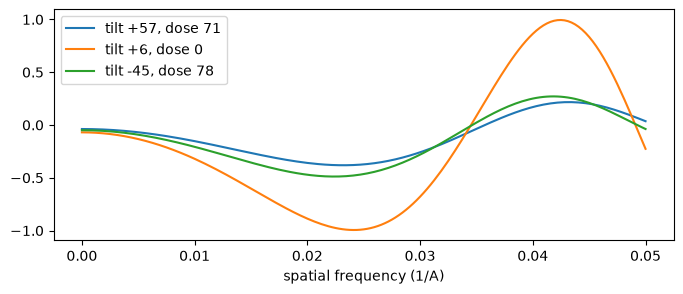

In [4]:
def microscope_filter(shape):
    ctf = -calculate_ctf_2d(
        defocus=defocus, astigmatism=astigmatism, astigmatism_angle=astigmatism_angle,
        voltage=VOLTAGE, spherical_aberration=SPHERICAL_ABERRATION, amplitude_contrast=AMPLITUDE_CONTRAST,
        phase_shift=0.0, pixel_size=PIXEL_SPACING, image_shape=shape, rfft=True, fftshift=False,
    )
    ctf[..., fftfreq_grid(image_shape=shape, rfft=True, fftshift=False, norm=True) > 0.5] = 0
    critical = _critical_exposure_grid(image_shape=shape, pixel_size=PIXEL_SPACING, rfft=True, fftshift=False)
    ctf = ctf * torch.exp(-_apply_voltage_correction(dose, VOLTAGE)[:, None, None] / (2 * critical))
    ctf = ctf * torch.cos(torch.deg2rad(tilt_angles))[:, None, None]
    return ctf.float().to(device)


ctf_patch = microscope_filter((PATCH, PATCH))
ctf_full = microscope_filter((NY, NX))

frequency = torch.fft.rfftfreq(NX) / PIXEL_SPACING
fig, ax = plt.subplots(figsize=(8, 3))
for t in [0, N_TILTS // 2, N_TILTS - 1]:
    ax.plot(frequency, ctf_full[t, 0].cpu(), label=f"tilt {tilt_angles[t]:+.0f}, dose {dose[t]:.0f}")
ax.set_xlabel("spatial frequency (1/A)")
ax.legend()
plt.show()

## Geometry: model box and rays

The tilt axis is y, so tilt i rotates by `Ry(tilt_i)`. The model box is a z slab of `THICKNESS` over the field of view,
widened in x so that every ray of every tilt enters and leaves through the z faces. Each detector pixel is one ray;
the line integral is the sum of evenly spaced (stratified, jittered during training) samples times the step length.

In [5]:
m_projection = Ry(tilt_angles)[..., :3, :3].float().to(device)

max_tilt = math.radians(tilt_angles.abs().max().item())
half_x = math.ceil((REF_NX / 2 + THICKNESS / 2 * math.sin(max_tilt)) / math.cos(max_tilt))
BOX_LOW = torch.tensor([-half_x, -(REF_NY // 2) - 0.5, -THICKNESS / 2], device=device)
BOX_HIGH = torch.tensor([half_x, REF_NY - REF_NY // 2 - 0.5, THICKNESS / 2], device=device)
BOX_CENTER, BOX_HALF = (BOX_LOW + BOX_HIGH) / 2, (BOX_HIGH - BOX_LOW) / 2
print("model box (x, y, z) in model voxels:", (2 * BOX_HALF).tolist())


def ray_samples(rotation, y, x, n_samples, jitter):
    # sample points along the rays through detector positions (y, x), clipped to the box, and the step length
    origin = rotation[:, 0] * x[:, None] + rotation[:, 1] * y[:, None]
    direction = rotation[:, 2]
    safe = torch.where(direction.abs() < 1e-6, torch.full_like(direction, 1e-6), direction)
    t1, t2 = (BOX_LOW - origin) / safe, (BOX_HIGH - origin) / safe
    t_near = torch.minimum(t1, t2).amax(-1)
    length = (torch.maximum(t1, t2).amin(-1) - t_near).clamp(min=0)
    u = ((torch.arange(n_samples, device=device) + 0.5) / n_samples).expand(len(x), n_samples)
    if jitter:
        u = u + (torch.rand_like(u) - 0.5) / n_samples
    t = t_near[:, None] + u * length[:, None]
    return origin[:, None] + t[..., None] * direction, length / n_samples


def n_samples_for(tilt, density):
    return max(8, math.ceil(density * THICKNESS / math.cos(math.radians(tilt_angles[tilt].item()))))

model box (x, y, z) in model voxels: [526.0, 160.0, 150.0]


## INR

Dense feature grids at several resolutions (cells of 12, 8, 6, 4, 3, 2 and 1 model voxels, 2 features per node),
concatenated and decoded by a 64-wide two-layer ReLU MLP with a softplus(β=20) output for positivity.

* **Smoothstep interpolation** instead of trilinear: no kinks at the grid nodes.
* **Random sub-cell offset per level and per model**: the even and odd models don't share grid positions, so grid
  artefacts don't inflate the half-map FSC.
* **Per-tilt offset and gain**: a background level and a contrast factor per image (gains normalised to geometric
  mean 1, so they can't trade off against the overall density scale).

In [6]:
def smoothstep_coordinates(u, n_nodes):
    g = (u + 1) / 2 * (n_nodes - 1)
    cell = g.floor()
    t = g - cell
    return (cell + t * t * (3 - 2 * t)) / (n_nodes - 1) * 2 - 1


class GridINR(nn.Module):
    def __init__(self, cell_sizes=CELLS, n_features=2, width=64):
        super().__init__()
        size = (2 * BOX_HALF).cpu()
        nodes = [torch.ceil(size / c).long() + 1 for c in cell_sizes]  # (x, y, z) nodes per level
        self.grids = nn.ParameterList([
            nn.Parameter(torch.empty(1, n_features, n[2] + 2, n[1] + 2, n[0] + 2).uniform_(-1e-4, 1e-4)) for n in nodes
        ])
        cell = torch.stack([2 / (n - 1).float() for n in nodes])  # (levels, 3) in [-1, 1] units
        self.register_buffer("extent", 1 + cell)
        self.register_buffer("offsets", (torch.rand(len(nodes), 3) - 0.5) * cell)
        self.register_buffer("n_nodes", torch.stack(nodes).float() + 2)
        self.mlp = nn.Sequential(
            nn.Linear(n_features * len(nodes), width), nn.ReLU(),
            nn.Linear(width, width), nn.ReLU(), nn.Linear(width, 1),
        )
        nn.init.constant_(self.mlp[-1].bias, -0.2)
        self.tilt_offset = nn.Parameter(torch.zeros(N_TILTS))
        self.tilt_log_gain = nn.Parameter(torch.zeros(N_TILTS))

    def tilt_gain(self):
        return torch.exp(self.tilt_log_gain - self.tilt_log_gain.mean())

    def forward(self, xyz):
        box = ((xyz - BOX_CENTER) / BOX_HALF).reshape(1, 1, 1, -1, 3)
        features = torch.cat([
            F.grid_sample(level, smoothstep_coordinates((box + offset) / extent, n), align_corners=True,
                          padding_mode="border").reshape(level.shape[1], -1)
            for level, offset, extent, n in zip(self.grids, self.offsets, self.extent, self.n_nodes)
        ])
        return F.softplus(self.mlp(features.T).reshape(xyz.shape[:-1]), beta=20)


print("parameters", sum(p.numel() for p in GridINR().parameters()), "vs data pixels", valid.sum().item())

parameters 31640689 vs data pixels 3516649


## Second-order TV prior

Mean Frobenius norm of the finite-difference Hessian at 65,536 random points anywhere in the box (including the missing
wedge directions, where it is the only constraint). The step is half the finest cell (10 Å), so it sees every scale
the grids can represent; dividing by step² keeps the strength independent of the step.

In [7]:
TV_STEP = min(CELLS) / 2


def second_order_tv(model, n_points=65536):
    points = torch.rand(n_points, 3, device=device) * (BOX_HIGH - BOX_LOW) + BOX_LOW
    steps = torch.eye(3, device=device) * TV_STEP
    values = model(points)
    hessian = []
    for i in range(3):
        hessian.append(model(points + steps[i]) - 2 * values + model(points - steps[i]))
        for j in range(i + 1, 3):
            mixed = (model(points + steps[i] + steps[j]) - model(points + steps[i] - steps[j])
                     - model(points - steps[i] + steps[j]) + model(points - steps[i] - steps[j])) / 4
            hessian += [mixed, mixed]
    return torch.sqrt(torch.stack(hessian).pow(2).sum(0) + 1e-12).mean() / TV_STEP ** 2

## Rendering and loss

A patch is rendered as one ray per detector pixel, then multiplied by the CTF of its tilt in Fourier space. The loss
is the masked MSE on the inner region (`MARGIN` from the patch edge, against CTF wrap-around). The stacks are padded so
patches may extend past the image: every pixel is then covered equally often.

In [8]:
def render_patch(model, tilt, y0, x0, density, jitter):
    # CTF-filtered projection of the PATCH x PATCH detector region with top-left pixel (y0, x0)
    pixels = torch.arange(PATCH, device=device)
    py, px = torch.meshgrid((pixels + y0 - NY // 2) * DETECTOR_SCALE, (pixels + x0 - NX // 2) * DETECTOR_SCALE, indexing="ij")
    points, dt = ray_samples(m_projection[tilt], py.flatten().float(), px.flatten().float(), n_samples_for(tilt, density), jitter)
    image = (model(points).sum(-1) * dt).reshape(PATCH, PATCH)
    image = torch.fft.irfftn(torch.fft.rfftn(image) * ctf_patch[tilt], s=(PATCH, PATCH))
    return image * model.tilt_gain()[tilt] + model.tilt_offset[tilt]


# detector pixels whose rays cross the saved volume (|x| <= REF_NX / 2, |z| <= THICKNESS / 2)
detector_x = (torch.arange(NX) - NX // 2).abs().float() * DETECTOR_SCALE
reach = REF_NX / 2 * torch.cos(torch.deg2rad(tilt_angles)) + THICKNESS / 2 * torch.sin(torch.deg2rad(tilt_angles.abs()))
sees_volume = (detector_x[None, :] <= reach[:, None] + 1)[:, None, :].expand(N_TILTS, NY, NX)
train_valid = valid & sees_volume

pad = (PATCH, PATCH, PATCH, PATCH)
stacks_padded = F.pad(stacks, pad)
masks_padded = {"train": F.pad(train_valid.float(), pad).to(device), "validation": F.pad(valid.float(), pad).to(device)}


def inner(y0, x0):
    return (slice(PATCH + y0 + MARGIN, PATCH + y0 + PATCH - MARGIN), slice(PATCH + x0 + MARGIN, PATCH + x0 + PATCH - MARGIN))


def patch_loss(model, half, patches, density, jitter, mask_name="validation"):
    total, count = 0.0, 0
    for tilt, y0, x0 in patches:
        prediction = render_patch(model, tilt, y0, x0, density, jitter)[MARGIN:-MARGIN, MARGIN:-MARGIN]
        rows, cols = inner(y0, x0)
        mask = masks_padded[mask_name][tilt, rows, cols]
        total = total + ((prediction - stacks_padded[half, tilt, rows, cols]) ** 2 * mask).sum()
        count = count + mask.sum()
    return total / count.clamp(min=1)


def random_patches(n, generator=None):
    return [(torch.randint(N_TILTS, (1,), generator=generator).item(),
             torch.randint(NY - PATCH + 1, (1,), generator=generator).item(),
             torch.randint(NX - PATCH + 1, (1,), generator=generator).item()) for _ in range(n)]


validation_patches = random_patches(3 * N_TILTS, torch.Generator().manual_seed(0))  # fixed, for comparability

## Sampler: whole images of random tilts, with gradient accumulation

Each optimiser step draws `TILTS_PER_STEP` random tilts and tiles each of their images with patches whose inner regions
cover every pixel exactly once (random tiling offset per tilt). The gradients of all patches are accumulated, rendering
`MICRO_BATCH` patches per backward pass, and normalised by the total number of masked pixels: one step then follows
the gradient of the full loss over those images. The TV term is added once per step.

With 2 random patches per step, the volume was updated from a couple of directions at a time: the predicted
projections showed horizontal lines and patchy blur, and the fit needed ~1500 steps.

In [9]:
def tiled_patches(tilts):
    inner_size = PATCH - 2 * MARGIN
    patches = []
    for tilt in tilts:
        oy, ox = torch.randint(inner_size, (2,)).tolist()
        for y in range(oy - inner_size, NY, inner_size):
            for x in range(ox - inner_size, NX, inner_size):
                if y + inner_size > 0 and x + inner_size > 0:
                    patches.append((tilt, y - MARGIN, x - MARGIN))
    return [patches[i] for i in torch.randperm(len(patches)).tolist()]


def accumulate_loss(model, half, patches, density, mask_name="train"):
    # backward per micro-batch, so memory only depends on MICRO_BATCH; returns the loss value
    mask_count = lambda tilt, y0, x0: masks_padded[mask_name][(tilt, *inner(y0, x0))].sum()
    total_count = sum(mask_count(*p) for p in patches).clamp(min=1)
    total = 0.0
    for i in range(0, len(patches), MICRO_BATCH):
        chunk = patches[i:i + MICRO_BATCH]
        count = sum(mask_count(*p) for p in chunk)
        if count == 0:
            continue
        loss = patch_loss(model, half, chunk, density, True, mask_name) * count / total_count
        loss.backward()
        total += loss.item()
    return total

## Training loop

Adam with separate learning rates for the grids (1e-2; they get sparse, small gradients), the MLP (1e-3) and the
per-tilt offset and gain (1e-2), a 10-step linear warm-up, and the checkpoint with the lowest loss on fixed patches of
the *other* half is kept.

In [10]:
def train(train_half, val_half, n_steps=N_STEPS, seed=1):
    torch.manual_seed(seed)
    model = GridINR().to(device)
    optimizer = torch.optim.Adam([
        {"params": model.grids.parameters(), "lr": GRID_LR},
        {"params": model.mlp.parameters(), "lr": MLP_LR},
        {"params": [model.tilt_offset, model.tilt_log_gain], "lr": TILT_LR},
    ])
    warmup = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1.0, (s + 1) / WARMUP))
    history = {"step": [], "train": [], "val": []}
    best = {"val": float("inf"), "step": 0}
    start = time.time()
    for step in range(1, n_steps + 1):
        optimizer.zero_grad()
        tilts = torch.randperm(N_TILTS)[:TILTS_PER_STEP].tolist()
        loss = accumulate_loss(model, train_half, tiled_patches(tilts), DENSITY)
        (TV_WEIGHT * second_order_tv(model)).backward()
        optimizer.step()
        warmup.step()
        if step % EVAL_EVERY == 0 or step == n_steps:
            with torch.no_grad():
                val = patch_loss(model, val_half, validation_patches, DENSITY, jitter=False).item()
            history["step"].append(step); history["train"].append(loss); history["val"].append(val)
            if val < best["val"]:
                best = {"val": val, "step": step, "state": copy.deepcopy(model.state_dict())}
            if device == "mps":
                torch.mps.empty_cache()  # release cached blocks so memory does not creep up over a run
            print(f"step {step} train {loss:.4f} val {val:.5f} ({time.time() - start:.0f} s)", flush=True)
    model.load_state_dict(best["state"])
    return model, history, best["step"]

## One INR per half

Even is trained on even and validated on odd (seed 1), odd the other way round (seed 2, so its grid offsets differ).
The saved runs: even stopped at step 190 with the validation loss still falling slowly (0.7931), odd best at step 170
(0.7961).

even loaded from runs/crop10_randtilts10_step190_even.pt


odd loaded from runs/crop10_randtilts10_odd.pt


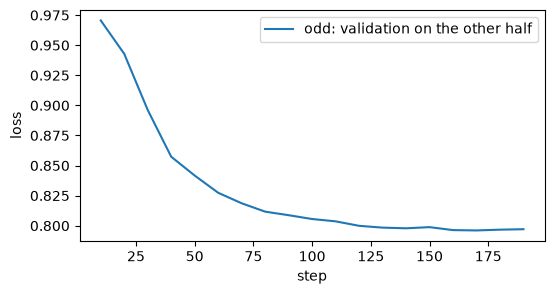

even: validation loss on odd 0.79308


odd: validation loss on even 0.79606


In [11]:
models, histories = {}, {}
for half, name in enumerate(["even", "odd"]):
    path = CHECKPOINTS[name]
    if path.exists() and not TRAIN:
        state = torch.load(path, map_location=device)
        models[name] = GridINR().to(device)
        models[name].load_state_dict(state.get("state", state))
        if "history" in state:  # older checkpoints hold only the weights
            histories[name] = state["history"]
        print(name, "loaded from", path)
    else:
        models[name], histories[name], best_step = train(half, 1 - half, seed=1 + half)
        torch.save({"history": histories[name], "best_step": best_step, "state": models[name].state_dict()}, path)
        print(name, "best step", best_step)
if histories:
    plt.figure(figsize=(6, 3))
    for name, history in histories.items():
        plt.plot(history["step"], history["val"], label=f"{name}: validation on the other half")
    plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()

with torch.no_grad():
    for half, name in enumerate(["even", "odd"]):
        print(f"{name}: validation loss on {['odd', 'even'][half]}",
              f"{patch_loss(models[name], 1 - half, validation_patches, DENSITY, jitter=False).item():.5f}")

## Render the volumes

At the 10 Å detector grid over the 0° field of view, 300 nm deep, in the units of the data (× the normalisation
scale). Density is bright.

In [12]:
def render_volume(model):
    nz = round(THICKNESS / DETECTOR_SCALE)
    z = ((torch.arange(nz, device=device) + 0.5) * DETECTOR_SCALE - THICKNESS / 2).float()
    y = ((torch.arange(NY, device=device) - NY // 2) * DETECTOR_SCALE).float()
    x = ((torch.arange(NX, device=device) - NX // 2) * DETECTOR_SCALE).float()
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    with torch.no_grad():
        slices = [model(torch.stack([xx, yy, torch.full_like(xx, zi)], -1).reshape(-1, 3)).reshape(NY, NX).cpu() for zi in z]
    return torch.stack(slices) * scale


def save_mrc(path, volume):
    with mrcfile.new(path, overwrite=True) as mrc:
        mrc.set_data(np.asarray(volume, dtype=np.float32))
        mrc.voxel_size = PIXEL_SPACING


volumes = {name: render_volume(model) for name, model in models.items()}
for name, volume in volumes.items():
    save_mrc(f"{PREFIX}_nb_{name}.mrc", volume)
print({name: tuple(v.shape) for name, v in volumes.items()})

{'even': (300, 320, 320), 'odd': (300, 320, 320)}


## Predicted projections

Full CTF-filtered projections of the even model (density 1 sample per model voxel), compared with the data. The
correlation with the odd half (not seen in training) is the honest measure; the even–odd correlation of the raw images
is what pure signal would reach.

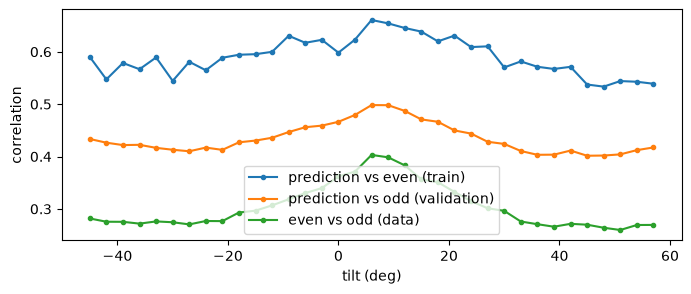

mean cc: train 0.590, validation 0.434, even-odd data 0.304


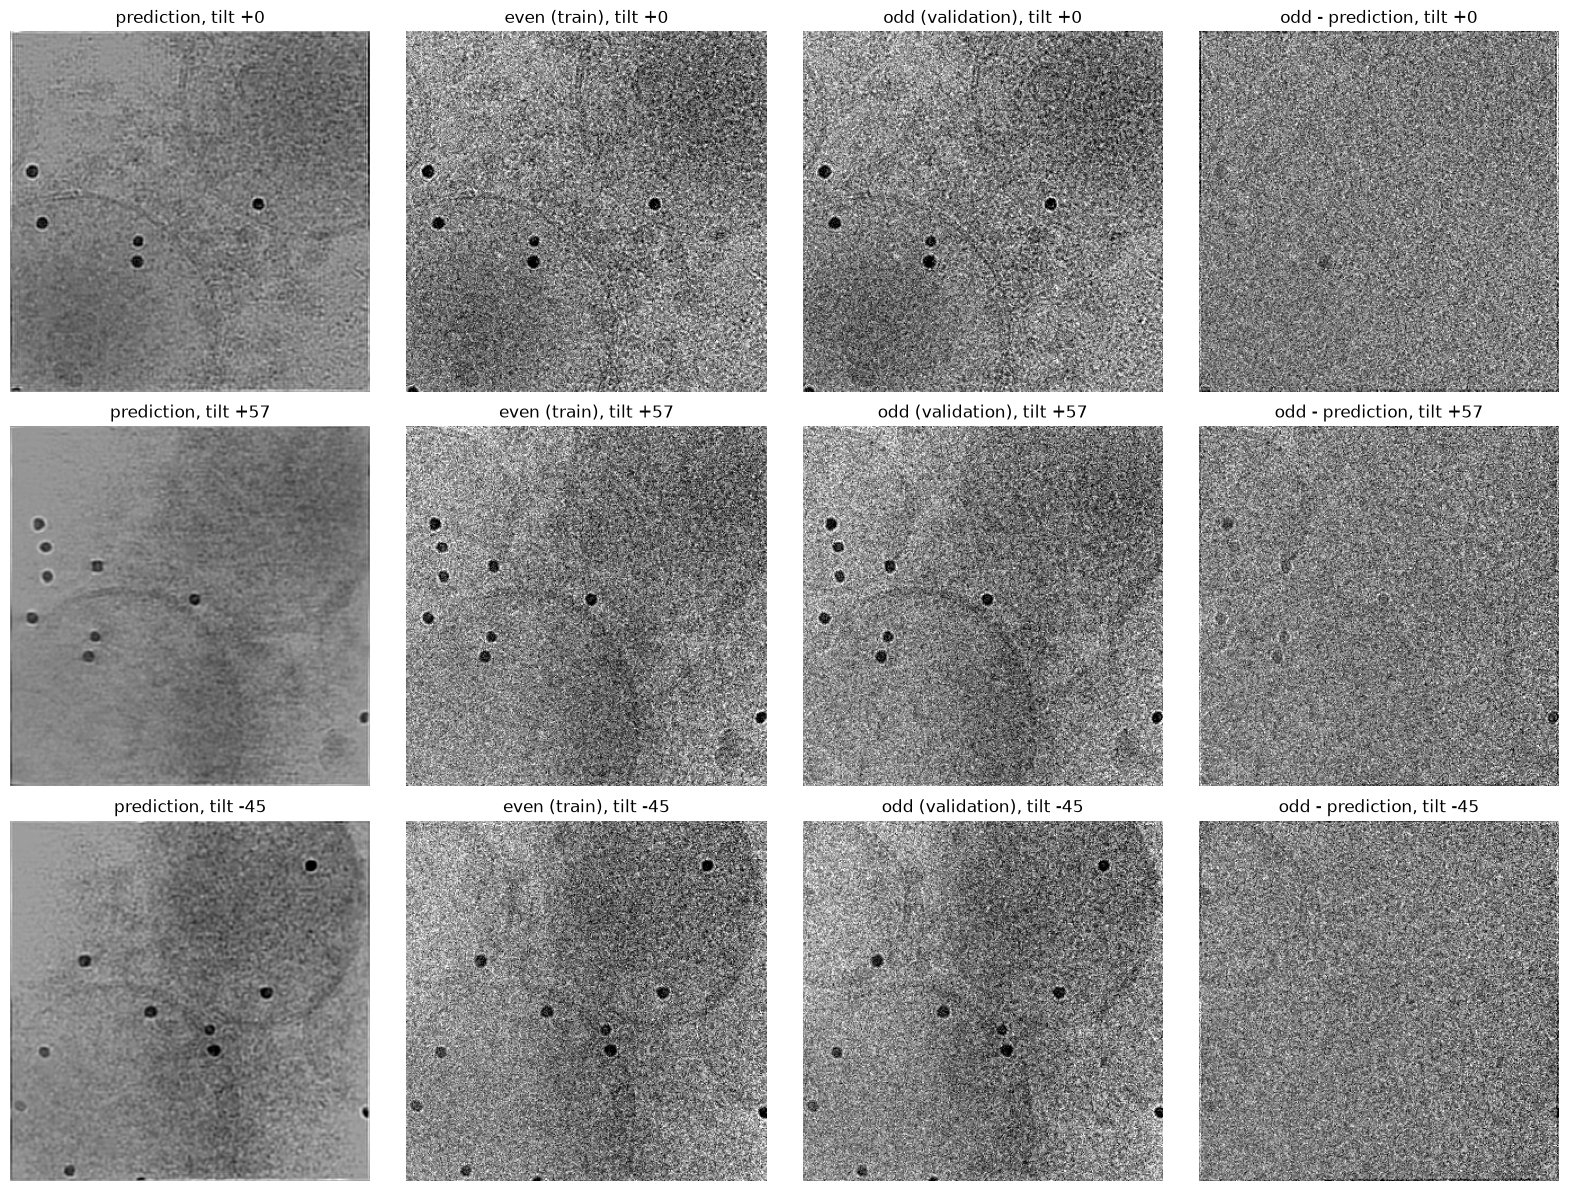

In [13]:
def render_projections(model, density=1.0, chunk=8192):
    det_y, det_x = torch.meshgrid((torch.arange(NY, device=device) - NY // 2) * DETECTOR_SCALE,
                                  (torch.arange(NX, device=device) - NX // 2) * DETECTOR_SCALE, indexing="ij")
    det_y, det_x = det_y.flatten().float(), det_x.flatten().float()
    images = []
    with torch.no_grad():
        for tilt in range(N_TILTS):
            n = n_samples_for(tilt, density)
            line = []
            for i in range(0, len(det_x), chunk):
                points, dt = ray_samples(m_projection[tilt], det_y[i:i + chunk], det_x[i:i + chunk], n, False)
                line.append(model(points).sum(-1) * dt)
            line = torch.cat(line).reshape(NY, NX)
            image = torch.fft.irfftn(torch.fft.rfftn(line) * ctf_full[tilt], s=(NY, NX))
            images.append((image * model.tilt_gain()[tilt] + model.tilt_offset[tilt]).cpu())
    return torch.stack(images)


predictions = render_projections(models["even"])
save_mrc(f"{PREFIX}_nb_even_projections.mrc", predictions * scale)
data = stacks.cpu()
cc = lambda a, b, m: np.corrcoef(a[m].numpy(), b[m].numpy())[0, 1]
table = np.array([[cc(predictions[t], data[0, t], valid[t]), cc(predictions[t], data[1, t], valid[t]),
                   cc(data[0, t], data[1, t], valid[t])] for t in range(N_TILTS)])
plt.figure(figsize=(8, 3))
for column, label in enumerate(["prediction vs even (train)", "prediction vs odd (validation)", "even vs odd (data)"]):
    plt.plot(tilt_angles, table[:, column], ".-", label=label)
plt.xlabel("tilt (deg)"); plt.ylabel("correlation"); plt.legend(); plt.show()
print("mean cc: train %.3f, validation %.3f, even-odd data %.3f" % tuple(table.mean(0)))

tilts = [int(tilt_angles.abs().argmin()), 0, N_TILTS - 1]
fig, ax = plt.subplots(len(tilts), 4, figsize=(16, 4 * len(tilts)))
for row, t in enumerate(tilts):
    lim = dict(vmin=np.percentile(data[1, t], 0.5), vmax=np.percentile(data[1, t], 99.5))
    for col, (name, image) in enumerate([("prediction", predictions[t]), ("even (train)", data[0, t]),
                                         ("odd (validation)", data[1, t]), ("odd - prediction", data[1, t] - predictions[t])]):
        ax[row, col].imshow(image, cmap="gray", **lim)
        ax[row, col].set_title(f"{name}, tilt {tilt_angles[t]:+.0f}")
        ax[row, col].set_axis_off()
plt.tight_layout(); plt.show()

## Combine the halves

Average, half-map FSC, and the FSC-weighted average (weight √(2 FSC / (1 + FSC)) per shell). The half-map FSC of two
INRs is inflated by the priors both halves share (positivity, TV), so treat it as an upper bound; the validation loss
is the reliable measure.

half-map FSC 0.143 at 36 A


even/odd volume cc 0.8510917796485977


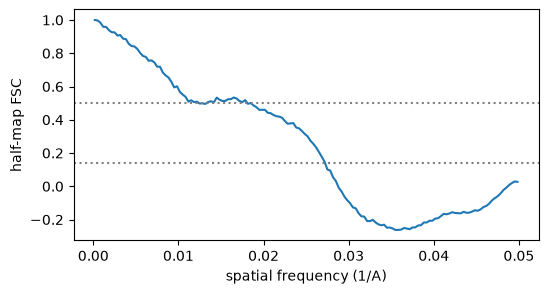

In [14]:
def frequency_grid(shape, pixel):
    axes = [torch.fft.fftfreq(shape[0]), torch.fft.fftfreq(shape[1]), torch.fft.rfftfreq(shape[2])]
    return torch.sqrt(sum(f ** 2 for f in torch.meshgrid(*axes, indexing="ij"))) / pixel


def half_map_fsc(a, b, pixel, n_shells):
    # soft cosine edge (8 voxels) against box-edge leakage
    window = torch.ones_like(a)
    for dim, n in enumerate(a.shape):
        w = torch.ones(n, dtype=a.dtype)
        r = min(8, n // 4)
        w[:r] = 0.5 - 0.5 * torch.cos(torch.pi * torch.arange(r) / r)
        w[-r:] = w[:r].flip(0)
        window = window * w.reshape([-1 if d == dim else 1 for d in range(a.ndim)])
    fa, fb = torch.fft.rfftn(a * window), torch.fft.rfftn(b * window)
    edges = torch.linspace(0, 0.5 / pixel, n_shells + 1)
    shell = torch.bucketize(frequency_grid(a.shape, pixel), edges[1:-1]).flatten()
    shell_sum = lambda v: torch.zeros(n_shells, dtype=torch.float64).index_add_(0, shell, v.flatten())
    fsc = shell_sum((fa * fb.conj()).real) / torch.sqrt(shell_sum(fa.abs() ** 2) * shell_sum(fb.abs() ** 2))
    return ((edges[:-1] + edges[1:]) / 2).numpy(), fsc.numpy()


even_volume, odd_volume = volumes["even"].double(), volumes["odd"].double()
average = (even_volume + odd_volume) / 2
k, fsc = half_map_fsc(even_volume, odd_volume, PIXEL_SPACING, n_shells=min(average.shape) // 2)
weight = np.sqrt(2 * np.clip(fsc, 0, None) / (1 + np.clip(fsc, 0, None)))
voxel_weight = torch.tensor(np.interp(frequency_grid(average.shape, PIXEL_SPACING).numpy(), k, weight))
fsc_weighted = torch.fft.irfftn(torch.fft.rfftn(average) * voxel_weight, s=average.shape)
save_mrc(f"{PREFIX}_nb_average.mrc", average)
save_mrc(f"{PREFIX}_nb_average_fsc_weighted.mrc", fsc_weighted)

below = np.where(fsc[1:] < 0.143)[0]
print("half-map FSC 0.143 at", f"{1 / k[1:][below[0]]:.0f} A" if len(below) else "Nyquist")
print("even/odd volume cc", np.corrcoef(even_volume.flatten(), odd_volume.flatten())[0, 1])
plt.figure(figsize=(6, 3))
plt.plot(k, fsc); plt.axhline(0.143, color="gray", ls=":"); plt.axhline(0.5, color="gray", ls=":")
plt.xlabel("spatial frequency (1/A)"); plt.ylabel("half-map FSC"); plt.show()

## Baseline: weighted back-projection

Real-space WBP of (even + odd) / 2 on the same grid: ramp filter along x (perpendicular to the tilt axis), no CTF
correction, sign flipped so density is bright as in the INR.

In [15]:
def weighted_back_projection(images, tilts, thickness_voxels):
    images = images - images.mean(dim=(-2, -1), keepdim=True)
    n_tilts, ny, nx = images.shape
    n_pad = 2 * nx
    filtered = torch.fft.irfft(torch.fft.rfft(images, n=n_pad, dim=-1) * torch.fft.rfftfreq(n_pad), n=n_pad, dim=-1)[..., :nx]
    z = torch.arange(thickness_voxels) - thickness_voxels / 2 + 0.5
    x = (torch.arange(nx) - nx // 2).float()
    gy = torch.arange(ny).float() / (ny - 1) * 2 - 1
    volume = torch.zeros(thickness_voxels, ny, nx)
    for t in range(n_tilts):
        angle = torch.deg2rad(tilts[t])
        detector_x = x[None, :] * torch.cos(angle) - z[:, None] * torch.sin(angle)  # (z, x), the INR convention
        gx = (detector_x + nx // 2) / (nx - 1) * 2 - 1
        grid = torch.stack([gx[:, None, :].expand(-1, ny, -1), gy[None, :, None].expand(thickness_voxels, -1, nx)], -1)
        volume += F.grid_sample(filtered[t][None, None].expand(thickness_voxels, 1, ny, nx), grid, align_corners=True)[:, 0]
    return -volume


wbp = weighted_back_projection((even + odd) / 2, tilt_angles, average.shape[0])
save_mrc(f"{PREFIX}_nb_wbp.mrc", wbp)

## Noise2Noise denoiser between the halves (optional)

The two INR volumes contain the same signal but mostly independent fitted noise (the grain in low-density regions),
so a small 3D U-Net trained to predict one half from the other removes it (as in cryo-CARE / Noise2Inverse).

* 1.46 M parameters, width 16, three downsamplings (receptive field ~70 voxels, well beyond the 6–10 voxel grain),
  residual output starting at the identity.
* 64³ patches, batch 4, both directions (even → odd and odd → even).
* Only flips that keep the missing wedge: y, and x with z together (180° about the tilt axis).
* The last 64 y rows are held out to pick the checkpoint.

Caveat: the odd half is the training target, so it no longer gives an independent check of the denoised volume. The
saved run: held-out loss 0.331 (identity) → 0.240 at step 2800 of 3000 (~1.3 h).

In [16]:
N2N_CHECKPOINT = RUNS / "crop10_randtilts10_n2n.pt"
N2N_STEPS, N2N_PATCH, N2N_BATCH, N2N_WIDTH, N2N_LR, N2N_EVAL_EVERY = 3000, 64, 4, 16, 3e-4, 200


class Block(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.net = nn.Sequential(nn.Conv3d(n_in, n_out, 3, padding=1), nn.LeakyReLU(0.1),
                                 nn.Conv3d(n_out, n_out, 3, padding=1), nn.LeakyReLU(0.1))

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.down = nn.ModuleList([Block(1, width), Block(width, 2 * width), Block(2 * width, 4 * width)])
        self.middle = Block(4 * width, 8 * width)
        self.up = nn.ModuleList([Block(12 * width, 4 * width), Block(6 * width, 2 * width), Block(3 * width, width)])
        self.out = nn.Conv3d(width, 1, 1)
        nn.init.zeros_(self.out.weight), nn.init.zeros_(self.out.bias)  # start at the identity

    def forward(self, x):
        skips, y = [], x
        for block in self.down:
            y = block(y)
            skips.append(y)
            y = F.avg_pool3d(y, 2)
        y = self.middle(y)
        for block, skip in zip(self.up, reversed(skips)):
            y = y.repeat_interleave(2, 2).repeat_interleave(2, 3).repeat_interleave(2, 4)
            y = block(torch.cat([y, skip], 1))
        return x + self.out(y)


# the denoiser works on the volumes as saved by the INR runs (normalised by the mean and std of the average)
halves = torch.stack([volumes["even"], volumes["odd"]]).float()
n2n_mean, n2n_std = halves.mean(0).mean(), halves.mean(0).std()
halves = ((halves - n2n_mean) / n2n_std).to(device)
nz, ny, nx = halves.shape[1:]
train_ny = ny - max(ny // 5, N2N_PATCH)  # rows from train_ny on are held out


def crop_pair(direction, z, y, x):
    s = (slice(z, z + N2N_PATCH), slice(y, y + N2N_PATCH), slice(x, x + N2N_PATCH))
    return halves[direction][s], halves[1 - direction][s]


def n2n_batch():
    inputs, targets = [], []
    for _ in range(N2N_BATCH):
        a, b = crop_pair(torch.randint(2, (1,)).item(), torch.randint(nz - N2N_PATCH + 1, (1,)).item(),
                         torch.randint(train_ny - N2N_PATCH + 1, (1,)).item(), torch.randint(nx - N2N_PATCH + 1, (1,)).item())
        if torch.rand(1) < 0.5:
            a, b = a.flip(1), b.flip(1)
        if torch.rand(1) < 0.5:
            a, b = a.flip(0, 2), b.flip(0, 2)
        inputs.append(a), targets.append(b)
    return torch.stack(inputs)[:, None], torch.stack(targets)[:, None]


generator = torch.Generator().manual_seed(0)
held_out = [crop_pair(d, torch.randint(nz - N2N_PATCH + 1, (1,), generator=generator).item(),
                      torch.randint(train_ny, ny - N2N_PATCH + 1, (1,), generator=generator).item(),
                      torch.randint(nx - N2N_PATCH + 1, (1,), generator=generator).item()) for d in (0, 1) for _ in range(16)]
held_in, held_target = (torch.stack(v)[:, None] for v in zip(*held_out))


@torch.no_grad()
def held_out_loss(model):
    return np.mean([F.mse_loss(model(held_in[i:i + N2N_BATCH]), held_target[i:i + N2N_BATCH]).item()
                    for i in range(0, len(held_in), N2N_BATCH)])


@torch.no_grad()
def denoise(model, volume, tile=96, overlap=32):
    # tiled inference with linear blending: no seams, bounded memory
    ramp = torch.minimum(torch.arange(1, tile + 1), torch.arange(tile, 0, -1)).float().clamp(max=overlap) / overlap
    weight = (ramp[:, None, None] * ramp[None, :, None] * ramp[None, None, :]).to(device)
    out, total = torch.zeros_like(volume), torch.zeros_like(volume)
    starts = [sorted({*range(0, n - tile, tile - overlap), n - tile}) for n in volume.shape]
    for z in starts[0]:
        for y in starts[1]:
            for x in starts[2]:
                s = (slice(z, z + tile), slice(y, y + tile), slice(x, x + tile))
                out[s] += model(volume[s][None, None])[0, 0] * weight
                total[s] += weight
    return out / total


denoiser = UNet(N2N_WIDTH).to(device)
if N2N_CHECKPOINT.exists() and not TRAIN:
    denoiser.load_state_dict(torch.load(N2N_CHECKPOINT, map_location=device, weights_only=False)["state"])  # our own file; older ones hold numpy scalars
    print("denoiser loaded from", N2N_CHECKPOINT)
else:
    torch.manual_seed(0)
    optimizer = torch.optim.Adam(denoiser.parameters(), lr=N2N_LR)
    best = {"val": float("inf"), "step": 0}
    print(f"identity held-out loss {held_out_loss(denoiser):.5f}")
    for step in range(1, N2N_STEPS + 1):
        inputs, targets = n2n_batch()
        loss = F.mse_loss(denoiser(inputs), targets)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        if step % N2N_EVAL_EVERY == 0 or step == N2N_STEPS:
            val = held_out_loss(denoiser)
            if val < best["val"]:
                best = {"val": val, "step": step, "state": copy.deepcopy(denoiser.state_dict())}
                torch.save({"state": best["state"], "step": step, "val": float(val)}, N2N_CHECKPOINT)
            print(f"step {step} train {loss.item():.5f} held-out {val:.5f}", flush=True)
            if device == "mps":
                torch.mps.empty_cache()
    denoiser.load_state_dict(best["state"])
print(f"held-out loss: identity 0.33061 (saved run), denoiser {held_out_loss(denoiser):.5f}")

denoised = {name: (denoise(denoiser, halves[h]) * n2n_std.to(device) + n2n_mean.to(device)).cpu()
            for h, name in enumerate(["even", "odd"])}
denoised_average = (denoised["even"] + denoised["odd"]) / 2
for name, volume in [*denoised.items(), ("average", denoised_average)]:
    save_mrc(f"{PREFIX}_nb_n2n_{name}.mrc", volume)

denoiser loaded from runs/crop10_randtilts10_n2n.pt


held-out loss: identity 0.33061 (saved run), denoiser 0.23975


## Visual comparison

xy sections (4-voxel slab, 40 Å) through the middle of the volume and an xz section (the missing wedge shows as
elongation along z).

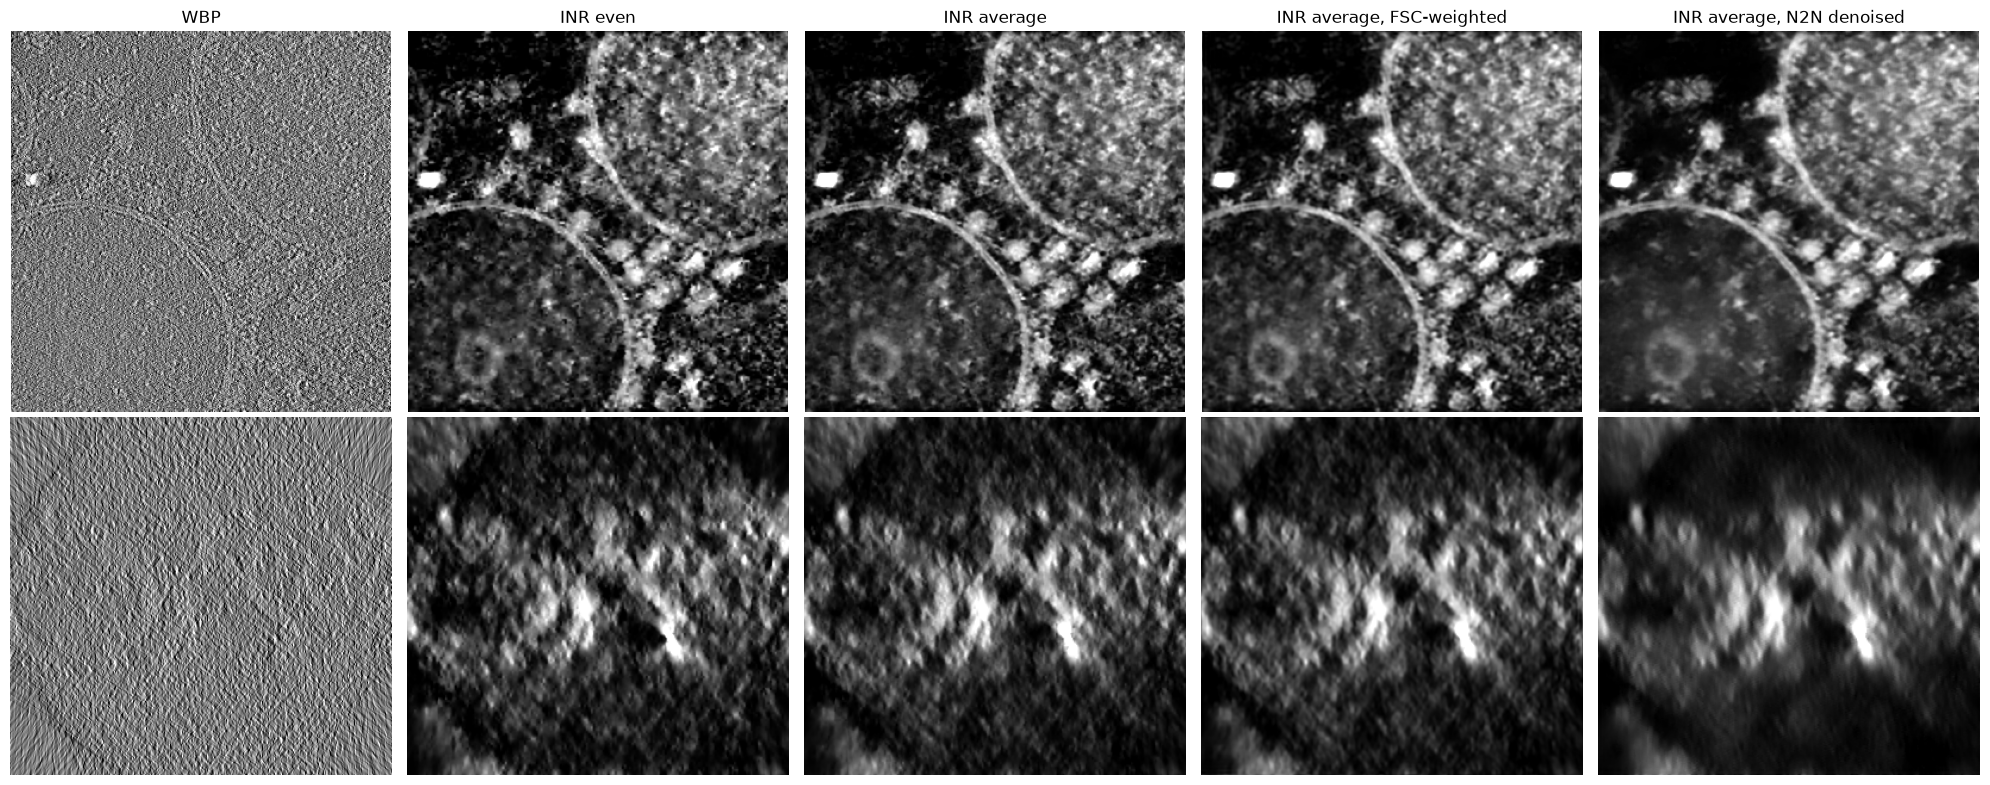

In [17]:
panels = [("WBP", wbp), ("INR even", volumes["even"]), ("INR average", average),
          ("INR average, FSC-weighted", fsc_weighted), ("INR average, N2N denoised", denoised_average)]
fig, ax = plt.subplots(2, len(panels), figsize=(4 * len(panels), 8), gridspec_kw={"height_ratios": [1, 1]})
middle = average.shape[0] // 2
for col, (name, volume) in enumerate(panels):
    volume = volume.float()
    xy = volume[middle - 2:middle + 2].mean(0)
    xz = volume[:, NY // 2 - 2:NY // 2 + 2].mean(1)
    for row, image in enumerate([xy, xz]):
        lim = dict(vmin=np.percentile(image, 1), vmax=np.percentile(image, 99.5))
        ax[row, col].imshow(image, cmap="gray", **lim)
        ax[row, col].set_axis_off()
    ax[0, col].set_title(name)
plt.tight_layout(); plt.show()

## Notes: results and what was tested

Even half on the 10 Å crop, validated on odd. *odd cc* / *even cc*: correlation of the volume with the odd / even INR
volume; *grain*: high-pass std in low-density regions (fitted noise); membrane contrast and FWHM from one arc.

| run | best val | odd cc | grain | membrane contrast / FWHM |
|---|---|---|---|---|
| 2 random patches per step, tiled coverage, TV₂ 3, 1500 steps | 0.803 | 0.390 | 0.0028 | 0.061 / 80 Å |
| **10 random tilts per step, TV₂ 3, 190 steps (this notebook)** | **0.793** | **0.412** | 0.0100 | 0.055 / 70 Å |
| 10 random tilts, TV₂ 5, 190 steps (still falling) | 0.793 | 0.395 | 0.0043 | 0.051 / 70 Å |
| 10 random tilts, TV₂ 1 (best at step 110) | 0.827 | 0.399 | 0.0135 | 0.059 / 60 Å |
| 10 random tilts, TGV² α₁ = 4 (best at step 110) | 0.828 | 0.398 | 0.0130 | 0.059 / 70 Å |
| 10 random tilts, TV₂ 3 with randomly rotated stencil | 0.793 | 0.410 | 0.0097 | 0.057 / 70 Å |

Half-map FSC (even vs odd INR) 0.143 at 36 Å; even/odd volume cc 0.851.

* **Sampler** (`inr_real.py sampler=...`): `random` (2 patches per step), `tiled` (every pixel once per epoch),
  `subsets` (ordered subsets: 5 interleaved groups of 7 tilts) and `random_tilts` (used here). 7 fixed interleaved
  tilts reached 0.792 at step 210 but showed a bouncing validation curve; random tilts gave a smooth one.
* **TV weight**: 3 is the best compromise. 5 has less grain but nearly doubles the axis-aligned excess in the
  predicted projections (horizontal lines); 1 and TGV² keep more noise and have a worse validation loss.
* **TGV²** (`tgv=1`): the helper field w stayed ≈ 0, so it acted like first-order TV.
* **Axis preference**: below ~36 Å the INR volumes have more power along x and y than along the diagonals (WBP and the
  raw data have none), and the projections near 0° show excess power along ky. It is not the smoothstep interpolation
  and not the TV₂ stencil (a randomly rotated stencil, `tv_rotate=1`, changed nothing). The axis-aligned feature grids
  are the main suspect, still to be tested.
* **Grain**: ~60 Å blobs elongated along z, not reproducible between the halves in empty regions, so mostly fitted
  noise. The N2N denoiser removes most of it, at the cost of slightly softer detail; not independently validated
  (a clean test would hold out tilts).
* **Dropped options** (still in `inr_real.py`): sub-pixel ray jitter (more noise), supersampled rendering (no
  difference), cosine learning-rate decay (−6% validation loss at 20 Å on long random-patch runs), warm start from a
  20 Å model with extra finer levels (`resume=`, `cells=`).